# Lab 2 : OD Matrices analytics

We want to find out which are more likely class of users of car sharing system. For this we compare the OD matrices obtained from different sources. 

## Setup of datasets and visualization

In [39]:
%pip install geopandas

  Using cached geopandas-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached pyogrio-0.13.0-cp311-abi3-manylinux_2_28_x86_64.whl.metadata (5.8 kB)
  Using cached pyproj-3.8.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached shapely-2.2.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (6.7 kB)
Using cached geopandas-1.2.0-py3-none-any.whl (368 kB)
Using cached pyogrio-0.13.0-cp311-abi3-manylinux_2_28_x86_64.whl (33.3 MB)
Using cached pyproj-3.8.0-cp313-cp313-manylinux_2_28_x86_64.whl (10.0 MB)
Using cached shapely-2.2.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (2.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]/4 [geopandas]
Note: you may need to restart the kernel to use updated packages.


In [45]:
import pymongo as pm
from pprint import pprint
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timezone
import geopandas as gpd
from shapely.geometry import box

### Car sharing - MongoDB

In [14]:
client = pm.MongoClient(
    'bigdatadb.polito.it',
    ssl=True,
    authSource='carsharing',
    username='ictts',
    password='Ict4SM22!',
    tlsAllowInvalidCertificates=True
)

In [15]:
db = client['carsharing']
pb_coll = db['ictts_PermanentBookings']
pb_coll_enjoy= db['ictts_enjoy_PermanentBookings']

In [16]:
list(pb_coll.find().limit(1))

[{'_id': ObjectId('5a3bb3af20c3dd47cf59003d'),
  'init_fuel': 53,
  'vendor': 'car2go',
  'exterior': 'GOOD',
  'vin': 'WME4533421K152664',
  'final_address': 'Corso Regina Margherita, 107, 10122 Torino TO',
  'engineType': 'CE',
  'final_date': datetime.datetime(2017, 11, 1, 0, 19, 45),
  'public_transport': {'duration': -1,
   'arrival_time': -1,
   'distance': -1,
   'arrival_date': -1},
  'final_loc': {'coordinates': [7.68634, 45.07567], 'type': 'Point'},
  'smartPhoneRequired': True,
  'init_time': 1509490770,
  'interior': 'GOOD',
  'init_address': 'Lungo Dora Napoli, 18A, 10152 Torino TO',
  'init_loc': {'coordinates': [7.68486, 45.08276], 'type': 'Point'},
  'driving': {'duration': 234, 'distance': 966},
  'final_time': 1509491985,
  'plate': '288/FF214SJ',
  'city': 'Torino',
  'final_fuel': 53,
  'init_date': datetime.datetime(2017, 10, 31, 23, 59, 30),
  'walking': {'duration': 746, 'distance': 982}}]

In [17]:
list(pb_coll_enjoy.find().limit(1))

[{'_id': ObjectId('5a3bb23920c3dd4716519e40'),
  'final_fuel': 56,
  'init_fuel': 57,
  'plate': 'EZ807DD',
  'car_category_id': 8,
  'driving': {'distance': 3948, 'duration': 545},
  'onClick_disabled': False,
  'init_loc': {'coordinates': [7.7029123, 45.07156], 'type': 'Point'},
  'walking': {'distance': 3776, 'duration': 2849},
  'virtual_rental_id': 361384,
  'car_category_type_id': 1,
  'carModelData': [99, 100, 141],
  'virtual_rental_type_id': 2,
  'final_address': 'Via Arcangelo Corelli, 41, 10154 Torino TO',
  'init_address': 'Corso Carlo Luigi Farini, 20, 10153 Torino TO',
  'final_time': 1509491472,
  'public_transport': {'distance': 4034,
   'duration': 1377,
   'arrival_time': 1509493666,
   'arrival_date': datetime.datetime(2017, 11, 1, 0, 47, 46)},
  'init_date': datetime.datetime(2017, 10, 31, 23, 58, 50),
  'final_date': datetime.datetime(2017, 11, 1, 0, 11, 12),
  'city': 'Torino',
  'vendor': 'enjoy',
  'init_time': 1509490730,
  'final_loc': {'coordinates': [7.70973

In [18]:
DoWMornings=pb_coll_enjoy.aggregate([
    {'$project': {
        'hour':{'$hour':'$init_date'},
        'day':{'$dayOfWeek':'$init_date'},
        'init_loc':1,
        'final_loc':1
    }},
    {'$match':{
        'hour': {'$gte':0,'$lt':12},
        'day':{'$gte':2,'$lt':7}
    }} ,
    {'$count':'tot'}
])

In [19]:
result = next(DoWMornings, None)
print(result)

{'tot': 23148}


### UnipolData

In [20]:
df_Uni_Info = pd.read_csv("data/Unipoldata/Info_TO.csv")
print(df_Uni_Info.head())       
print(df_Uni_Info.info())  

df_Uni_Trips = pd.read_csv("data/Unipoldata/Trips_OD_TO.csv")
print(df_Uni_Trips.head())       
print(df_Uni_Trips.info())  

   id_veicolo commerciale  eta_approx genere
0           1           N          47      M
1           2           N          54      M
2           3           N          34      F
3           4           N          81      M
4           5           N          23      M
<class 'pandas.DataFrame'>
RangeIndex: 37949 entries, 0 to 37948
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id_veicolo   37949 non-null  int64
 1   commerciale  37949 non-null  str  
 2   eta_approx   37949 non-null  int64
 3   genere       37949 non-null  str  
dtypes: int64(2), str(2)
memory usage: 1.2 MB
None
   id_veicolo  id_viaggio        istante_start  lat_start  lon_start  \
0           1           2  2024-08-27 21:15:03     45.069      7.698   
1           1           4  2024-08-27 21:22:47     45.069      7.698   
2           1           5  2024-08-28 08:16:42     45.083      7.675   
3           1           6  2024-08-28 11:47:37     45.

### IMQ

## Question 1

### Import of Lab1 filtering

In [25]:
Q = 0.90

In [26]:
def load_wtime(db, coll, carsharing=True):
    if carsharing:
        pipe = [
            {
                "$match": {
                    "driving.duration": {"$gt": 0},
                    "driving.distance": {"$gt": 0}
                }
            },
            {
                "$project": {
                    "_id": 0,
                    "init_time": 1,
                    "final_time": 1,
                    "duration": "$driving.duration",
                    "day": {
                        "$dateToString": {
                            "date": "$init_date",
                            "format": "%Y-%m-%d"
                        }
                    },
                    "week": {"$isoWeek": "$init_date"},
                    "iso_year": {"$isoWeekYear": "$init_date"},
                    "dow": {"$isoDayOfWeek": "$init_date"},
                    "hour": {"$hour": "$init_date"},
                    "vendor": 1,
                    "init_address": 1,
                    "final_address": 1,
                    "plate": 1,
                    "init_loc": 1,
                    "final_loc": 1,
                    "driving": 1,
                    "walking": 1,
                    'init_date':1
                }
            }
        ]

    else:
        raise NotImplementedError(
            "Non-carsharing data processing is not implemented yet."
        )

    collection = db[coll] if isinstance(coll, str) else coll
    df = pd.DataFrame(collection.aggregate(pipe, allowDiskUse=True))

    if df.empty:
        print("Warning: MongoDB query returned no documents.")
        return df

    df["duration_min"] = df["duration"] / 60

    df["driving_distance_km"] = df["driving"].apply(
        lambda x: x["distance"] / 1000
        if isinstance(x, dict) else np.nan
    )

    df["walking_duration_min"] = df["walking"].apply(
        lambda x: x["duration"] / 60
        if isinstance(x, dict) else np.nan
    )

    return df



def best_zone(x, q=Q, log=True, threshold=False, min_duration=1.0):
    x = np.sort(np.asarray(x, dtype=float))
    if threshold:
        x = x[x >= min_duration]
    else:
        x = x[x >= 0]
    n = len(x)
    if n == 0:
        return np.nan, np.nan
    k = int(np.ceil(q * n))
    t = np.log(x) if log else x
    widths = t[k - 1:] - t[:n - k + 1]
    i = np.argmin(widths)
    return x[i], x[i + k - 1]


def keep_best_zone(df, q=Q, col="duration_min", log=True, threshold=False):
    a, b = best_zone(df[col].values, q, log, threshold)
    return df[df[col].between(a, b)].copy(), (a, b)


def get_filtered_data(db,coll,q=Q,carsharing=True,verbose=True,return_extra=False):
    raw = load_wtime(db=db,coll=coll,carsharing=carsharing)

    if raw.empty:
        raise ValueError("No data returned by MongoDB.")

    filtered, zone = keep_best_zone(raw, q=q)

    if verbose:
        a, b = zone
        n0, n1 = len(raw), len(filtered)
        percentage = n1 / n0 if n0 else 0

        print(
            f"zone = [{a:.1f}, {b:.1f}] min "
            f"-> {n1}/{n0} gardés ({percentage:.1%})"
        )

    if return_extra:
        return filtered, {"raw": raw, "zone": zone}

    return filtered

In [27]:
df_Car2Go = get_filtered_data(
    db=db,
    coll=pb_coll,
    q=0.90,
    carsharing=True
)

zone = [5.0, 22.0] min -> 35276/39190 gardés (90.0%)


In [28]:
df_Enjoy = get_filtered_data(
    db=db,
    coll=pb_coll_enjoy,
    q=0.90,
    carsharing=True
)

zone = [5.0, 22.6] min -> 32158/35726 gardés (90.0%)


### See if filtering needed

### a - Compute OD matrices on different periods

Méthode :
- Définir un zonage spatial fixe pour toute la ville.
- Associer une zone d'origine et une zone de destination à chaque trajet.
- Regrouper les trajets selon leur période temporelle.
- Calculer une matrice OD pour chaque période.

In [41]:
def prepare_od_data(df, epsg=32632):
    data = df.copy()
    # longitude and latitude
    data["origin_lon"] = data["init_loc"].apply(lambda x: x["coordinates"][0])
    data["origin_lat"] = data["init_loc"].apply(lambda x: x["coordinates"][1])

    data["destination_lon"] = data["final_loc"].apply(lambda x: x["coordinates"][0])
    data["destination_lat"] = data["final_loc"].apply(lambda x: x["coordinates"][1])

    # Project coordinates into a metric CRS
    origins = gpd.GeoSeries(gpd.points_from_xy(data["origin_lon"], data["origin_lat"]),crs="EPSG:4326").to_crs(epsg=epsg)

    destinations = gpd.GeoSeries(gpd.points_from_xy(data["destination_lon"], data["destination_lat"]),crs="EPSG:4326").to_crs(epsg=epsg)

    data["start_x"] = origins.x
    data["start_y"] = origins.y
    data["end_x"] = destinations.x
    data["end_y"] = destinations.y

    data["init_date"] = pd.to_datetime(data["init_date"])

    return data

In [53]:
def make_od_grid(data, h=1000):
    # Fixed grid origin
    x0 = np.floor(min(data["start_x"].min(), data["end_x"].min()) / h) * h

    y0 = np.floor(min(data["start_y"].min(), data["end_y"].min()) / h) * h

    x_max = max(data["start_x"].max(), data["end_x"].max())
    y_max = max(data["start_y"].max(), data["end_y"].max())

    n_cols = int(np.floor((x_max - x0) / h)) + 1
    n_rows = int(np.floor((y_max - y0) / h)) + 1

    # Create grid polygons
    polygons = []

    for row in range(n_rows):
        for col in range(n_cols):
            x = x0 + col * h
            y = y0 + row * h

            polygons.append(box(x, y, x + h, y + h))

    zones = gpd.GeoDataFrame(
        {"zone_id": range(n_rows * n_cols)},
        geometry=polygons,
        crs="EPSG:32632"
    )

    # Assign origins and destinations
    trips = data.copy()

    # Remove missing or infinite coordinates
    cols = ["start_x", "start_y", "end_x", "end_y"]

    trips = trips.replace([np.inf, -np.inf], np.nan)
    trips = trips.dropna(subset=cols).copy()

    origin_col = np.floor((trips["start_x"] - x0) / h).astype(int)
    origin_row = np.floor((trips["start_y"] - y0) / h).astype(int)

    destination_col = np.floor((trips["end_x"] - x0) / h).astype(int)
    destination_row = np.floor((trips["end_y"] - y0) / h).astype(int)

    trips["origin"] = origin_row * n_cols + origin_col
    trips["destination"] = destination_row * n_cols + destination_col

    return trips, zones

In [54]:
def compute_od_by_period(trips, zones, period="day"):
    # Define temporal aggregation
    frequencies = {
        "hour": "h",
        "day": "D",
        "week": "W-SUN", #from monday to sunday
        "month": "MS"
    }

    if period not in frequencies:
        raise ValueError(
            f"Unknown period: {period}. "
            f"Choose from {list(frequencies.keys())}"
        )

    freq = frequencies[period]
    od_results = {}

    # Group trips by temporal period
    grouped = trips.groupby(pd.Grouper(key="init_date", freq=freq))

    for period_label, group in grouped:
        if group.empty:
            continue

        # OD count matrix
        OD_counts = pd.crosstab(
            group["origin"],
            group["destination"]
        )

        # Keep all zones, including empty zones
        OD_counts = OD_counts.reindex(
            index=zones.index,
            columns=zones.index,
            fill_value=0
        )

        OD_counts.index.name = "origin"
        OD_counts.columns.name = "destination"

        # Joint probability matrix
        N = len(group)
        OD_probability = OD_counts / N

        # Conditional destination probabilities
        origin_counts = OD_counts.sum(axis=1)

        conditional_OD = OD_counts.div(
            origin_counts.replace(0, np.nan),
            axis=0
        )

        od_results[period_label] = {
            "OD_counts": OD_counts,
            "OD_probability": OD_probability,
            "conditional_OD": conditional_OD,
            "n_trips": N
        }

    return od_results

In [68]:
trips = prepare_od_data(df_Car2Go)
trips, zones = make_od_grid(trips, h=2000)

OD_by_day = compute_od_by_period(trips, zones, period="day")
OD_by_hour = compute_od_by_period(trips, zones, period="hour")
OD_by_week = compute_od_by_period(trips, zones, period="week")
OD_by_month = compute_od_by_period(trips, zones, period="month")

In [69]:
def plot_od_comparison(OD_by_day, OD_by_hour, OD_by_week, OD_by_month,
                      matrix="OD_counts", cmap="viridis",
                      figsize=(20, 5)):

    datasets = {
        "Day": OD_by_day,
        "Hour": OD_by_hour,
        "Week": OD_by_week,
        "Month": OD_by_month
    }

    fig, axes = plt.subplots(
        1, 4,
        figsize=figsize,
        constrained_layout=True
    )

    for ax, (name, dataset) in zip(axes, datasets.items()):

        if not dataset:
            ax.set_title(f"{name} - No data")
            ax.axis("off")
            continue

        # Select first available period
        period_label = next(iter(dataset))
        od_matrix = dataset[period_label][matrix]

        # Each matrix has its own color scale
        im = ax.imshow(
            od_matrix,
            cmap=cmap,
            aspect="auto"
        )

        ax.set_title(f"{name}\n{period_label}")
        ax.set_xlabel("Destination zone")
        ax.set_ylabel("Origin zone")

        # Individual colorbar for each matrix
        fig.colorbar(
            im,
            ax=ax,
            label=matrix,
            shrink=0.8
        )

    plt.show()


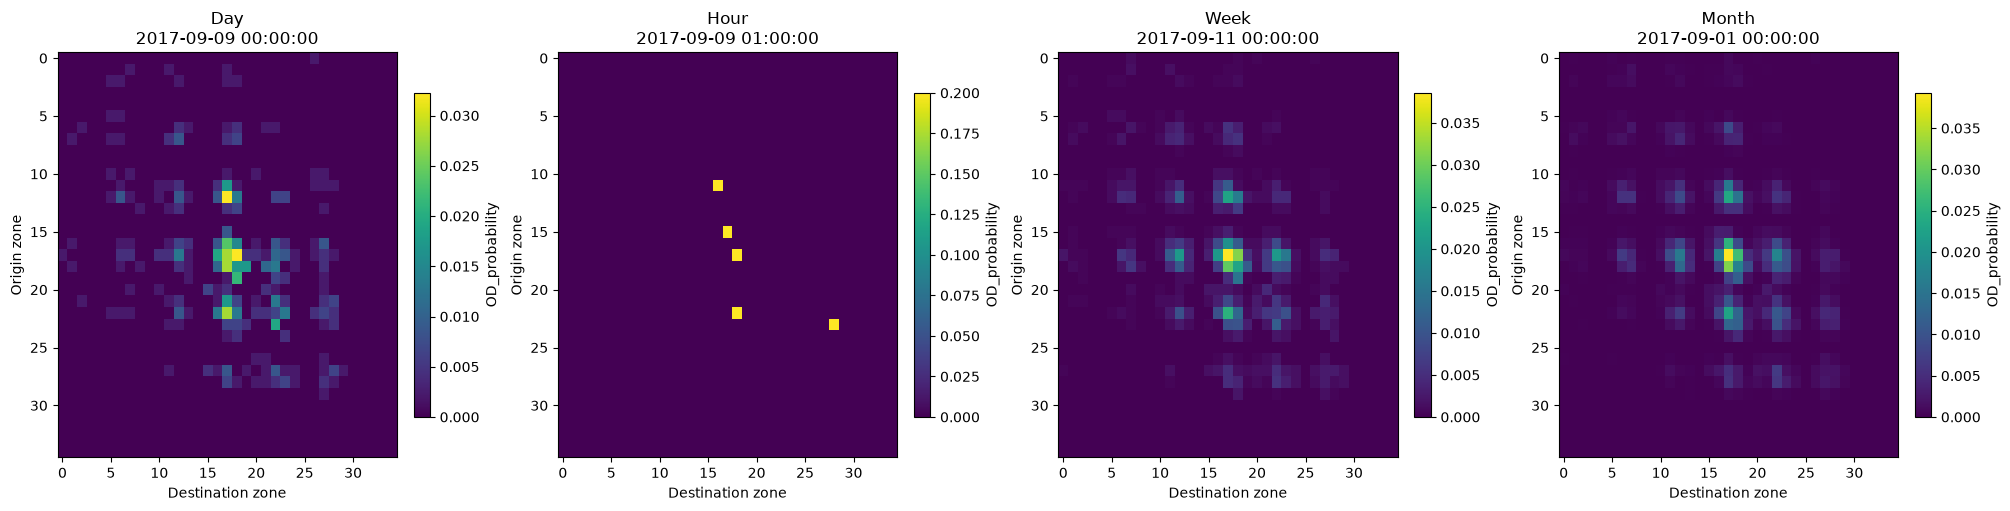

In [77]:
plot_od_comparison(
    OD_by_day,
    OD_by_hour,
    OD_by_week,
    OD_by_month,
    matrix="OD_probability"
)

Bien vérifier normalisation et les différents types de matrices